# The Classical Ising Model

Here we'll take a break from quantum mechanics and discuss a simpler, classical model of a ferromagnet called the Ising model. This model is comprised of a lattice of classical spins which can point either up or down, but don't have any of the quantum properties of entanglement or superposition. Once we understand this simpler classical spin model, we'll be ready to upgrade it back to a quantum model for the rest of the project.

## The Model

To start, we'll work with a square lattice with $L \times L$ sites total; at each site $j$, there is a spin labeled by $s_j$ which can take on the values of $\pm 1$. In a ferromagnet, each spin interacts with its neighbors to try and align its spin with the spin of neighbors around it. Therefore, we can write down the following expression for the energy:

$$ \mathcal{H} = -J \sum_{\langle j,k \rangle} s_j s_k. $$

The parameter $J>0$ is a positive number which sets how strongly the spins interact; the angle brackets $\langle j,k\rangle$ under the sum means we sum over all nearest neighbor pairs; therefore, each spin generally interacts with 4 others (except for those on the boundary which have fewer neighbors). Just looking at two neighboring spins: if they point the same direction, I either multiply $(+1)(+1)$ or $(-1)(-1)$, so this term contributes $-J$ to the energy. If they point in opposite directions, I multiply $(+1)(-1)$, and this term contributes $+J$. Since physical systems generally want to lower their energy, this shows that spins generally favor aligning.

We can also add an extra term which accounts for an external magnetic field. Spins will favor aligning along the direction of the external magnetic field, so this can bias the system more towards a particular direction (up/down). This gives us the full (classical) Hamiltonian:

$$ \mathcal{H} = -J \sum_{\langle j,k \rangle} s_j s_k - h \sum_j s_j. $$

Similar to before, $h$ sets the strength of the magnetic field, and if $s_j$ and $h$ have the same sign, then the energy will be lowered, demonstrating the preference to align with the field. With this full model, we can see that in order to absolutely minimize the energy, we should align every spin along the direction of the field uniformly, and the resulting energy per site should be $E_0/L^2 = -2J-h$.

The final piece of the puzzle is thermodynamics: our spin system sits in a environment held at a fixed temperature $T$. We assume that the environment is MUCH larger than the system; by exchanging energy with the environment, our spin system can change its energy, but the environment is basically unaffected (imagine putting leftovers in a giant fridge; the food gets cold, but the fridge doesn't really get any warmer). We'll explore the effect of changing the temperature more below, but for now just know that temperature determines how often random thermal fluctuations happen in the system; even if a spin is aligned with its neighbors, it could randomly get enough energy from the environment to flip its spin the wrong way, even if only briefly.

## Metropolis Monte Carlo Algorithm

The ground state of our system is defined by knowing the orientation of every spin when the system has its lowest energy. To find this, we are going to use a numerical technique called the **Metropolis Monte Carlo** algorithm. Here's how this works:

0. Start with a lattice with every spin randomly oriented up or down and compute the total energy $E$.
1. Pick a random site and flip its spin; compute the new energy $E'$ and change in energy $\Delta \equiv E'-E$.
2. If the energy decreases ($\Delta<0$), go back to step 1.
3. If the energy increases ($\Delta>0$), then pick a random number uniformly between 0 and 1. If the random number is more than $e^{-\Delta/T}$, then flip the spin back. This guarantees that if the ratio $\Delta/T$ is very large, the exponential will be very small, so I'll almost always flip the spin back. We want to keep the "bad" changes sometimes, in order to avoid getting stuck in configuration which may be a local minimum in energy, but not the global minimum.

If we repeat the procedure above a whole bunch of times, then eventually the system will settle down into its equilibrium state; we know we've reached that point when randomly flipping a spin can't lower the energy any further.

**NB:** The exponential factor in step 3 has a name, the **Boltzmann factor**, which appears often in thermodynamics and statistical physics. Basically, the Boltzmann factor $e^{-E/T}$ determines the probability of a system being in a state with has energy $E$. You may have also noticed that the units are wrong: $E$ is an enegy (Joules) but $T$ is a temperature (Kelvin); this is because I have chosen to not continually write the Boltzmann constant $k_B \approx 1.38\cdot10^-23 J/K$ all over the place because it does nothing but make computations harder. It's basically just a conversion factor between units of temperature and energy, so I've chosen to just work in non-SI units where I can set $k_B=1$.

## Building the Algorithm

First thing to do: load in necessary packages, and initialize a random number generator for us to use later.

In [1]:
import numpy as np
import numpy.linalg as la

import matplotlib.pyplot as plt
%matplotlib inline
import matplotlib as mpl
mpl.rc('xtick', direction='in', top=True)
mpl.rc('ytick', direction='in', right=True)
mpl.rc('xtick.minor', visible=True)
mpl.rc('ytick.minor', visible=True)

## Random number generator 
rng = np.random.default_rng()
## Functions for animation
from time import sleep
from IPython import display

The first step of our algorithm is to make an array of randomly oriented spins.

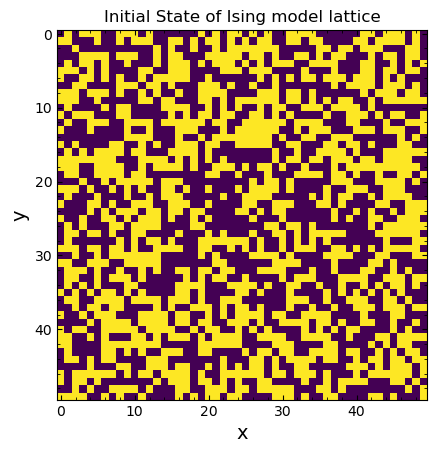

In [2]:
def random_lattice(L, rng) :
    '''
    Creates a square, LxL matrix with each value randomly assigned to +/- 1
    Inputs:
        L: dimension of array
        rng: random number generator to use
    Outputs:
        LxL array of +/- 1s as type 'int'
    '''
    A = np.sign(rng.normal(size=(L,L)))  
    A[A==0] = 1;   ## in case we generate a zero, make it +1
    return A.astype(int)

A = random_lattice(50,rng);
plt.imshow(A,aspect=1);
plt.xlabel('x',fontsize=14);
plt.ylabel('y',fontsize=14);
plt.title('Initial State of Ising model lattice');

Next, we need to determine the energy difference $\Delta E$ as a result of flipping a single spin. This only depends on the original site, and its nearest neighbors, since the rest of the lattice is unchanged.

 - When a spin is flipped, it only changes the energy from 4 "bond" terms in the Hamiltonian: one for each nearest neighbor. If two spins were aligned and become anti-aligned, the energy goes from $-J$ to $+J$, for a change of $+2J$ If two spins were anti-aligned and become aligned, the energy goes from $+J$ to $-J$, for a change of $-2J$.
 - For the field term: if a spin is flipped from along the external field, to against the field, the energy changes from $-h$ to $+h$, for a change of $+2h$. For the opposite change, the energy changes by $-2h$.

To deal with spins on the boundary, we'll use periodic boundary conditions, which effectively makes bonds between the top and bottom rows, and between the leftmost and rightmost columns. Technically, this means the model is defined on a torus (like a donut). In the code below, this shows up as using modular division `%` to wrap around indices to the other side of the lattice when I try to go "out-of-bounds" for the terms on the edges.

The following cell has functions to compute $\Delta E$ for flipping a single lattice site, and to randomly choose and flip a point in the lattice. I've also included functions to compute the total energy per spin and average magnetization in the lattice so we can track that as it iterates.

In [3]:
def DeltaE(lattice, J, H, j, k):
    '''
    Returns the energy difference in the lattice that results from flipping
    the spin at indices j,k
    Inputs:
        lattice: lattice of spin values to consider
        J: coupling strength between lattice bonds in Hamiltonian
        H: coupling strength to external magnetic field
        j,k: row and column, respectively, of the site to flip
    Outputs:
        difference in energy between the lattice with and without the spin 
        at site j,k flipped
    '''
    L = len(lattice);
    return 2*H*lattice[j,k]+2*J*lattice[j,k]*(lattice[(j+1)%L,k]+lattice[(j-1)%L,k]+lattice[j,(k+1)%L]+lattice[j,(k-1)%L])

def flip_point(lattice, J, H, T, rng):
    '''
    Chooses a random site on lattice and flips the spin there, 
    according to the appropriate transition probabilities.
    Inputs:
        lattice: NxN array of spins +/-1
        J: coupling strength between lattice bonds in Hamiltonian
        H: coupling strength to external magnetic field
        T: temperature of Ising model system
        rng: random number generator to be used to 
    Outputs:
        None; only (possibly) changes the value of one spin in lattice
    '''
    ## Pick a random point
    L = len(lattice);
    j = rng.integers(0,high=L); k = rng.integers(0,high=L); 
    
    ## Calculate dE and decide whether or not to flip the point
    dE = DeltaE(lattice,J,H,j,k);
    if dE<0:
        ## Flip if energy is decreased by flip
        lattice[j,k]=-lattice[j,k];
    elif rng.random()<np.exp(-dE/T):
        ## If energy is increased, only flip if the random number is less than e^(-dE/T)
        lattice[j,k]=-lattice[j,k];
        
    return();

def computeE(lattice, J, H):
    '''
    Computes the energy of a lattice, using the Ising Hamiltonian
    with coupling constants J, H
    Inputs:
        lattice: NxN array of spins +/-1
        J: coupling strength between lattice bonds in Hamiltonian
        H: coupling strength to external magnetic field
    Outputs:
        Energy value for lattice
    '''
    E=0;
    L = len(lattice);
    for i in range(L):
        E+=np.sum(-J*lattice[i,:]*lattice[(i+1)%L,:]-J*lattice[i,:]*np.roll(lattice[i,:],-1)-H*lattice[i,:]);  
    return E

def computeM(lattice):
    '''
    Computes the average magnetization per spin of a given lattice
    configuration.
    '''
    L = len(lattice);
    return np.sum(lattice)/(L**2);

Now we'd like to take our random lattice from before, and run enough iterations to converge to the ground state, but how many is enouch iterations? We have $L^2$ spins, and in order to give every spin a change to be flipped and have its effects propagate through the system, we want each spin to flip $\propto L$ times, so I'll start with $3L^3$ iterations, but you're welcome to mess with this number to see how it effects things. 

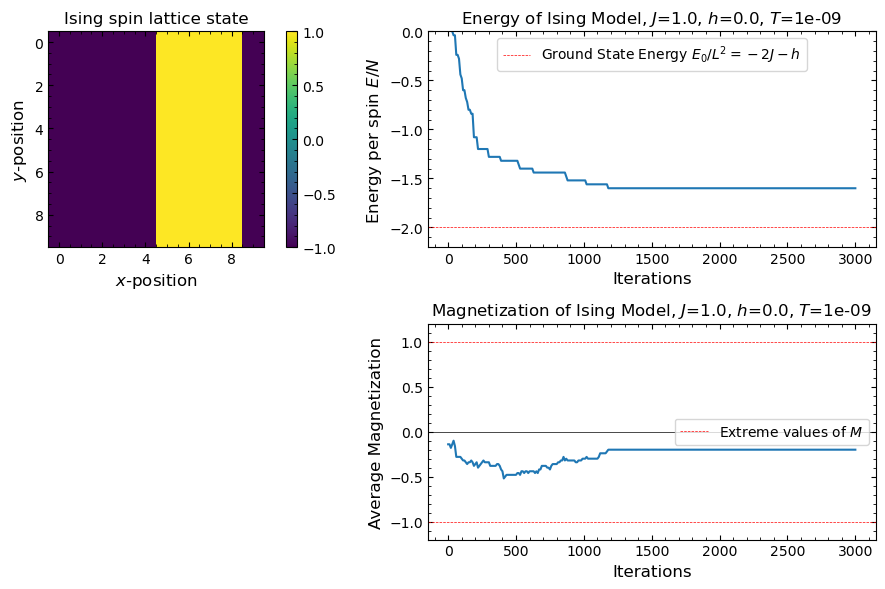

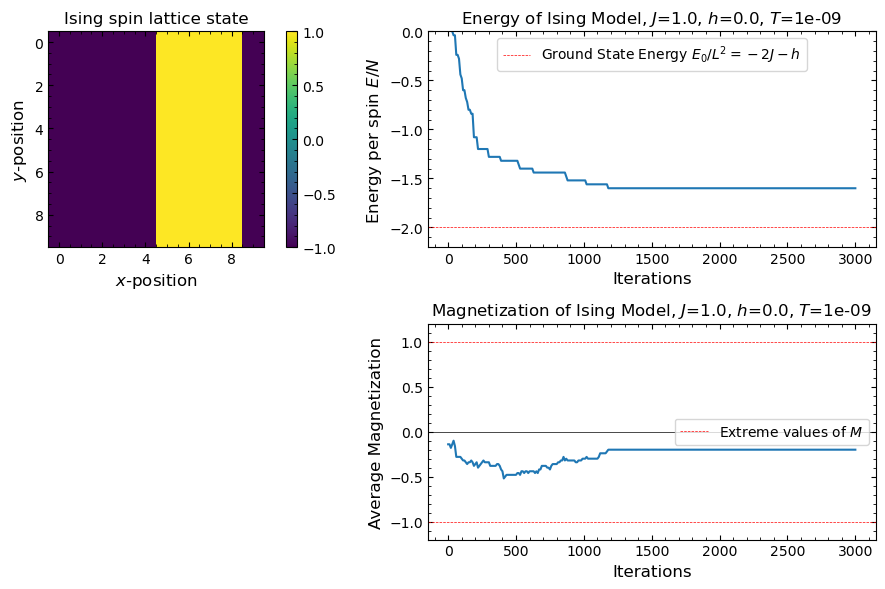

In [4]:
## Set couplings here 
J = 1.; h = 0.; 
E0 = -2*J-np.abs(h);
## Set temperature, use a small finite value instead of 0 
## to avoid errors in exp(-Δ/T)
Temp = 1e-9; 
## Set system size and initialize lattice
L = 10;
A = random_lattice(L,rng);

## Parameters for Metropolis algorithm
maxiter = 3*L**3;
checkpts = 10;
updatepts = 100;
narr = range(0,maxiter+1,checkpts);
Earr = np.zeros(len(narr));
Marr = np.zeros(len(narr));

## Initial parameters
c = 0;
Earr[c] = computeE(A, J, h); 
Marr[c] = computeM(A);

## Set up plotting
fig1 = plt.figure(figsize=(10,6)); 
ax1 = fig1.add_subplot(221); ax2 = fig1.add_subplot(222); ax3 = fig1.add_subplot(224);

ax1.set_xlabel('$x$-position',fontsize=12);
ax1.set_ylabel('$y$-position',fontsize=12);
ax1.set_title('Ising spin lattice state');

ax2.set_xlabel("Iterations",fontsize=12);
ax2.set_ylabel("Energy per spin $E/N$",fontsize=12);
ax2.set_title(f"Energy of Ising Model, $J$={J}, $h$={h}, $T$={Temp}",fontsize=12);
ax2.axhline(E0,color='red',ls='--',lw=0.5,label='Ground State Energy $E_0/L^2=-2J-h$');
ax2.axhline(0,color='black',ls='-',lw=0.5);
ax2.set_ylim(1.1*E0, 0);
ax2.legend(loc='upper center');
line_E, = ax2.plot(narr, Earr);

ax3.set_xlabel("Iterations",fontsize=12);
ax3.set_ylabel("Average Magnetization",fontsize=12);
ax3.set_title(f"Magnetization of Ising Model, $J$={J}, $h$={h}, $T$={Temp}",fontsize=12);
ax3.axhline(0,color='black',ls='-',lw=0.5);
ax3.axhline(-1,color='red',ls='--',lw=0.5,label='Extreme values of $M$');
ax3.axhline(1,color='red',ls='--',lw=0.5);
ax3.set_ylim(-1.2, 1.2);
ax3.legend(loc='right');
line_M, = ax3.plot(narr, Marr);

for i in range(maxiter):
    flip_point(A, J, h, Temp, rng);
    if i%checkpts==0:
        c+=1;
        ## Keep track of energy and magnetizations
        Earr[c] = computeE(A, J, h);
        Marr[c] = computeM(A);

    if i%updatepts==0:
        display.clear_output(wait=True)

        iModel=ax1.imshow(A,aspect=1,vmin=-1,vmax=1); 
        line_E.set_ydata(Earr/L**2);
        line_M.set_ydata(Marr);
        
        fig1.tight_layout();

        display.display(plt.gcf())
        sleep(0.1);

display.clear_output(wait=True)

iModel=ax1.imshow(A,aspect=1,vmin=-1,vmax=1); 
line_E.set_ydata(Earr/L**2);
line_M.set_ydata(Marr);

fig1.tight_layout();
fig1.colorbar(iModel, ax=ax1);

display.display(plt.gcf())
## I don't know why it displays twice at the end, and I don't know how to fix it. 
## Sorry about that.

### Practice Problem

Your task now is to mess around with this simulation and see how changing various parameters changes the results. For each simulation run, I'd recommend saving the output image either with `plt.savefig` (check the documentation if you're not sure what to do) or by just taking a screenshot and saving them all in a folder somewhere. Make sure to give the files descriptive names so that you know what parameters were used to compute each output.

1. Run the simulation a few times with its default parameters ($J=1, h=0, T=10^{-6}$); you should notice the final output isn't always the exact same. There should be three classes of outputs:
   
    1. All spins point up
    2. All spins point down
    3. Two distinct regions of up and down, split about 50/50

    The first two demonstrate what is called **spontaneous symmetry breaking**; in the random configuration at the beginning the system has no preference for up/down, and if you performed a transformation which flipped every spin, you would get a system that looks pretty much the same. As the algorithm runs, the system randomly picks a direction to align with, breaking the up/down symmetry that the random starting state has.

    The third outcome is an artifact of simulating a finite system. Since we only have $L^2$ sites, you can sometimes get into a scenario where there are approximately equal numbers of up and down in large regions, and neither domain is able to flip the other, so we get **domain walls**, but we can fix these!

1. If you want to avoid domain walls, try biasing the spins in a particular direction with a small magnetic field by setting `h` to some small value. If you flip the sign of `h`, it should bias things the other way, and flip the outcome that direction. You also might notice that the simulations converges more quickly with the additional bias.
2. Now with a small field ($h\sim 10^{-6}$), try turning up the temperature and saving the data from runs at $T=\{0.1, 1, 2, 5\}$ and make note of the differences. You should find that at higher temperatures, the system takes longer to converge, and may never reach the ground state. We want to quantify the break between two very distinct behaviors - states that converge to the ground state (eventually) and states which fail to ever reach the ground state, even at infinite time.

### Practice Problem

Below is the code to compute the energy $E$ and magnetization $M$ across a range of temperature points; in the Monte Carlo algorithm, I've set it up to average $E$ and $M$ over the last 20% of iterations instead of just the very last iteration in order to smooth out random fluctuations. Run this code (it may take a few seconds, depending on how large you set `A` and `maxiter`) and then create the following plots:

1. Plot of energy `Earr` versus temperature `tarr`. Include a horizontal line at the absolute ground state energy `E0` (hint: check out `ax.axhline`).
2. Plot of average magnetization `Marr` versus temperature `tarr`. Include a horizontal line at the maximum value of $+1$.
3. Plot of heat capacity $C_V$ versus temperature. The heat capacity measures how much energy a system can gain or lose as its temperature changes; in other words, the temperature derivative of energy: $C_V(T) = \frac{dE}{dT}$. The simplest way to take a derivative when you have discrete, numeric data is to revert back to the basic definition of a derivative as a finite difference: change in $f(x)$ divided by change in $x$. This can be done in python using `np.diff`; I'll compute the heat capacity `Carr` as `np.diff(Earr)/np.diff(tarr)`. However, this returns an array with 1 fewer value than we started with, since `np.diff` subtracts pairs of values, so you'll have to plot it against the new temperature `tarr_2` which containts the midpoints between each pair of points in `tarr`.
6. Plot of the temperature derivative of magnetization; this is sort of like a *magnetic susceptibility* $\chi$, but that's not technically correct so I'll just call this $\frac{\partial M}{\partial T}$. This is again computed with a finite difference, so plot this with `tarr2` for the $x$-data.

On the last two plots, add a vertical line indicating the temperature of the absolute minimum of $\frac{\partial M}{\partial T}$ and the absolute maximum of $C_V(T)$. (Hint: there are many ways you could do this, but I would start with `np.argmin` or `np.argmax`). These points where $M$ and $E$ are changing most rapidly (i.e. have the largest derivative) indicate the **critical temperature** $T_C$, or the point where the system has transitioned from an ordered **ferromagnet** into a disordered **paramagnet**. If we could simulate a truly infinite system, we would expect that these peaks in $C_V$ and $\frac{\partial M}{\partial T}$ diverge to infinity, which is a hallmark of phase transitions: at exactly the critical point, some measurable thermodynamic quantity has a singularity (or in other words, a point where the behavior isn't mathematically well defined).

It turns out, the transition temperature $T_C$ for this model can be derived exactly without computer simulations; thankfully, someone much smarter than us has already done this, so we can just quote the result. Once you've identified your simulation's estimates for the transition temperature, [check here](https://en.wikipedia.org/wiki/Ising_model#Onsager's_exact_solution) to see how close you got.

If you have the patience for it, once you have this all done, run the simulation for a few minutes by setting `L`, `maxiter`, and `tpts` a bit higher; this should smooth out the data and make things look nicer, as well as hopefully give a closer estimate for the transition temperature.


In [5]:
## Set couplings here 
J = 1.; h = 1e-2; 
E0 = -2*J-np.abs(h);

## Set system size and initialize lattice
L = 12;
A = random_lattice(L,rng);

## Parameters for Metropolis algorithm
maxiter = 5*L**4;

## Temperature axis 
tmin = 0.1; tmax = 8; tpts = 30;
tarr= np.linspace(tmin, tmax, tpts);

Earr = np.zeros(tpts);
Marr = np.zeros(tpts);
for t in range(tpts):
    Temp = tarr[t]; ## Set Temp
    
    ## run Metropolis algorithm from above
    for i in range(maxiter):
        flip_point(A, J, h, Temp, rng);
        if i>0.8*maxiter:
            ## Keep track of energy and magnetizations near the end of sim
            Earr[t] += computeE(A, J, h);
            Marr[t] += abs(computeM(A));   
        
    ## average over last few sim runs by dividing by number of saved values
    Earr[t] /= ((maxiter-0.8*maxiter)*L**2)
    Marr[t] /= (maxiter-0.8*maxiter)

## Compute heat capacity C and dMdT, here called chi (χ)
Carr = np.diff(Earr)/np.diff(tarr);
chi_arr = np.diff(Marr)/np.diff(tarr);
tarr2 = (tarr[:-1]+tarr[1:])/2;

T_C =  2.4155172413793102 +/- 0.13620689655172413
T_C =  2.4155172413793102 +/- 0.13620689655172413


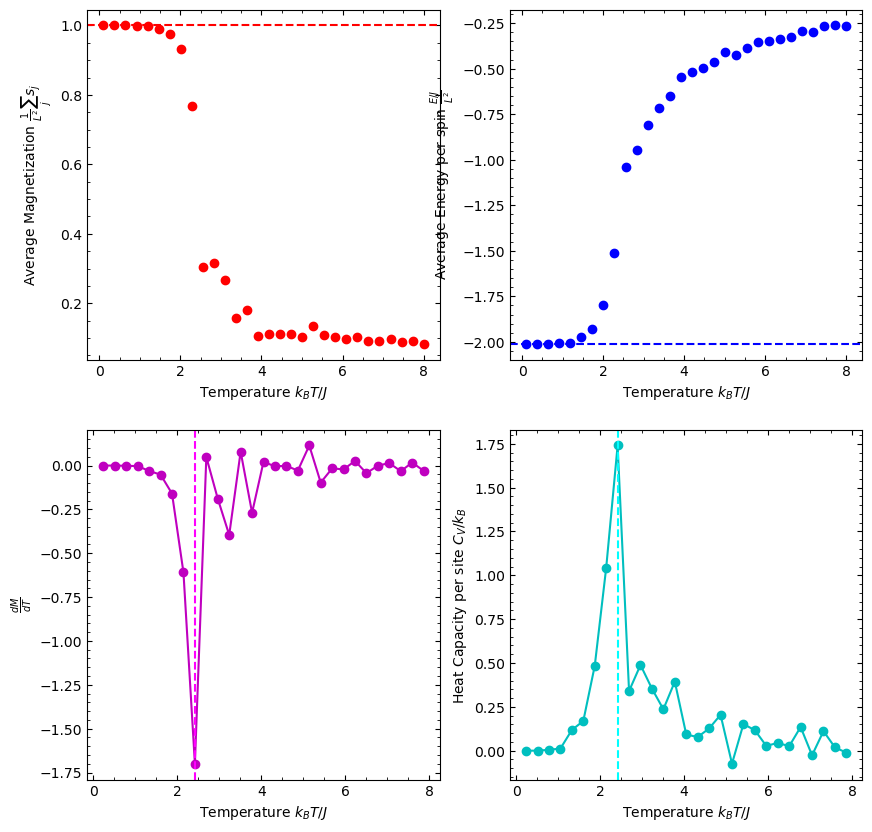

In [6]:
fig_mag = plt.figure(figsize=(10,10));
ax_mag = fig_mag.add_subplot(221);
ax_en = fig_mag.add_subplot(222);
ax_chi = fig_mag.add_subplot(223);
ax_c = fig_mag.add_subplot(224);

ax_mag.plot(tarr, Marr, 'ro');
ax_mag.set_xlabel(r"Temperature $k_B T/J$");
ax_mag.set_ylabel(r"Average Magnetization $ \frac{1}{L^2}\sum_j s_j$");
ax_mag.axhline(1, ls='dashed', color='red');

ax_en.plot(tarr, Earr, 'bo');
ax_en.set_xlabel(r"Temperature $k_B T/J$");
ax_en.set_ylabel(r"Average Energy per spin $\frac{E/J}{L^2}$");
ax_en.axhline(E0, ls='dashed', color='blue');

ax_chi.plot(tarr2, chi_arr, 'mo-');
ax_chi.set_xlabel(r"Temperature $k_B T/J$");
ax_chi.set_ylabel(r"$\frac{dM}{dT}$");

Tc_1 = tarr2[np.argmin(chi_arr)];
ax_chi.axvline(Tc_1, ls='dashed', color='magenta');
print("T_C = ", Tc_1, "+/-", np.diff(tarr)[0]/2);

ax_c.plot(tarr2, Carr, 'co-');
ax_c.set_xlabel(r"Temperature $k_B T/J$");
ax_c.set_ylabel(r"Heat Capacity per site $C_V/k_B$");

Tc_2 = tarr2[np.argmax(Carr)];
ax_c.axvline(Tc_2, ls='dashed', color='cyan');
print("T_C = ", Tc_2, "+/-", np.diff(tarr)[0]/2)

## Optional: Finite Size Scaling

To get a more precise estimate of $T_C$ from our simulation, we should run the simulation with as many spins as possible, since the exact value from Onsager is for an infinite system. However, more spins means a slower simulation, so we're limited with what we can do. Try running the simulation with different values for $L$ starting from around 8 and going up as high as you can without getting horribly impatient with waiting for it to finish (but don't be afraid to let it run for a few minutes). After each run, make a note of the $T_C$ estimated from both $C_V$ and $\frac{dM}{dT}$ and plot those values vs. the values of $L$; you should (hopefully) find that the values get closer to the exact answer for larger $L$. 

## Soapbox: Scales, Dimensions, and Units

An important tool to understanding any physics problem is knowing what the relevant scales are in the problem. For example, if I want to study the forces between a proton and electron in a hydrogen atom, the important energy scale is the strength of the electromagnetic Coulomb force. I should technically account for the gravitational forces between them, since they are both massive particles, but the energy scale for gravity is 1,000,000,000,000,000,000,000,000,000,000,000,000x smaller than the Coulomb force (that is 36 zeros, or [1 undecillion](https://simple.wikipedia.org/wiki/Names_of_large_numbers)).

In this problem, the dominant energy scale is set by the interaction strength $J$ between spins. For this reason, I can just set $J=1$ and consider everything else in units of $J$. There are two other competing energy scales to understand: the magnetic field coupling $h$ and the thermal energy $k_B T$. In the absence of a magnetic field, I can estimate the energy it takes to flip a spin away from the ordering is on the order of $\sim 4J$ (since each spin has 4 neighbors to interact with), so if the system is at or above that temperature, then there is enough thermal energy to prevent the system from ever ordering. If I add a field $h$, this stabilizes the order in the direction of the field, and now it takes more energy/higher temperature to have a disordered system. Just by comparing the magnitudes of energy scales in the problem, I can pretty accurately guess the state of the system.

These energy scales also impact how one should communicate data. If one group does an experiment with $J=2$ and reports $T_C=4.6\pm 0.2$, but another group does the same kind of experiment, but with $J=100$ and reports $T_C=231 \pm 5$, who is right? Both of them are, because it's only the ratio $k_B T_C/J$ which is universally true. For that reason, you'll often see data for things like this presented with dimensionless, unitless quantities on the axes, so that it's clear to compare across experiments/papers. For example, instead of plotting with temperature $T$ on the $x$-axis, I would plot $k_B T/J$ on the $x$-axis, the unitless ratio of energy scales. However, for these simulations, those are entirely equivalent because I've chosen to work in units where $J=k_B=1$.

If you skipped this wall of text because it said "soapbox," I can't say I blame you, but the short version is that you should always be thinking about scales in every physics problem, so that you can use the right units for the job, both to make your calculation simpler and to make comparing and communicating results easier. 

## Summary

Here we've seen a classical model of interacting spins which favor aligning with each other, and along an external applied field. To demonstrate this, you've run a Monte Carlo simulation to find the equilibrium state of the system subject to a wide variety of input parameters. By running this simulation over a range of temperatures, we can get numeric estimates for the energy $E$ and magnetization $M$ for this system as a function of $T$, then use those quantities to estimate the transition temperature by identifying the temperature where thermodynamic measurables like $C_V$ diverge. 

The next step is to upgrade this classical Ising model back into a quantum Ising model by considering quantum spins capable of superposition and entanglement. In this version of the model, the spins will interact with their neighbors and try to align the $z$-component of their spins, but if we point the magnetic field along the $\hat{x}$-axis, this frustrates the state of the spins and creates quantum entanglement. 

As a final note, I would *highly* encourage you to save this notebook somewhere you'll remember in a few years, because there's a good chance you'll have to do a very similar assignment in your own thermodynamics/statistical physics class later down the line; most of what is here is adapted from my own homework assignments from an undergrad coding course and my graduate statistical phyics class.